<a href="https://colab.research.google.com/github/cjlantigua-hue/gmp-audit-risk-dashboard/blob/main/notebooks/04_ml_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 · ML Model: Will This Finding Come Back?
**Project:** GMP Audit Findings Risk Dashboard · **Company:** Meridian Pharma (fictional)

The risk score (Phase 3) describes a finding **as it stands today**. This notebook asks a forward-looking question
that the score cannot answer:

> **When a finding is first raised, how likely is the same problem to be cited again on the same item within 12 months?**

A QA lead could use this on day one to decide which CAPAs need a deeper root-cause investigation, rather than a quick fix.

### Ground rules (to keep the model honest)
1. **Only use information available when the finding is logged.** No CAPA status, close dates, risk score, or anything
   else that is only known later. Using future information is called **data leakage**; it makes a model look great on
   paper and fail in real use.
2. **Split by time, not at random.** Train on older findings, test on newer ones, exactly as the model would be used.
3. **Beat a simple baseline.** If a one-line rule does as well as the model, the model isn't worth deploying.

**How to run:** run notebooks 01–02 first, then `Runtime → Run all`.

## 1. Setup

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import joblib, sklearn

from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, precision_score, recall_score)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = '/content/drive/MyDrive/gmp-audit-risk-dashboard'
except ImportError:
    PROJECT = './gmp-audit-risk-dashboard'

MODELS_DIR, FIG_DIR = f'{PROJECT}/models', f'{PROJECT}/figures'
os.makedirs(MODELS_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)
SNAPSHOT = pd.Timestamp('2026-09-30')
SEED = 42

df = pd.read_csv(f'{PROJECT}/data/processed/findings_scored.csv',
                 parse_dates=['audit_date', 'open_date', 'due_date', 'close_date'])
print(f'{len(df)} findings loaded | scikit-learn {sklearn.__version__}')

GRAY, INK, MUTED = '#b4b2a9', '#0b0b0b', '#52514e'
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': GRAY,
                     'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelcolor': MUTED,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.grid': True, 'grid.color': '#ecebe6',
                     'axes.axisbelow': True, 'legend.frameon': False})

Mounted at /content/drive
1365 findings loaded | scikit-learn 1.6.1


## 2. Define the target
**`recurs_12m` = True** if the same category is cited again **on the same affected item at the same site** in an audit
within 365 days after this finding's audit.

We can only know the answer for findings that have a full year of follow-up, so findings audited after
**2025-09-30** are excluded from training and testing (their outcome isn't known yet).

In [2]:
later = df.groupby(['site_id', 'category', 'affected_item'])['audit_date'].apply(np.sort).to_dict()
df['recurs_12m'] = [((d > r.audit_date) & (d <= r.audit_date + pd.Timedelta(days=365))).any()
                    for r in df.itertuples() for d in [later[(r.site_id, r.category, r.affected_item)]]]

labeled = df[df['audit_date'] <= SNAPSHOT - pd.Timedelta(days=365)].copy()
print(f'Findings with a known outcome: {len(labeled)} of {len(df)}')
print(f'Share that recurred within 12 months: {labeled.recurs_12m.mean():.0%}')

Findings with a known outcome: 896 of 1365
Share that recurred within 12 months: 66%


## 3. Features (known at the moment the finding is logged)

| Used | Why it's safe |
|---|---|
| site, process area, category, severity, audit type, product type | Recorded when the finding is written |
| `prior_occurrence_count` | Counts only **earlier** audits (rule 5.4) |
| `description` (text) | Written when the finding is raised |

| **Not** used | Why |
|---|---|
| status, close_date, days_open, effectiveness_check, is_overdue, closed_late | Only known later |
| risk_score, risk_tier, impact, exposure | Built partly from CAPA status, so they leak future information |

In [3]:
CATEGORICAL = ['site_name', 'process_area', 'category', 'severity', 'audit_type', 'product_type']
NUMERIC     = ['prior_occurrence_count']
TEXT        = 'description'
FEATURES    = CATEGORICAL + NUMERIC + [TEXT]
TARGET      = 'recurs_12m'

LEAKY = {'status', 'close_date', 'days_open', 'effectiveness_check', 'is_overdue', 'closed_late',
         'risk_score', 'risk_tier', 'impact', 'exposure', 'status_points', 'overdue_points', 'recurrence_points'}
assert not LEAKY & set(FEATURES), 'A leaky column is in the feature list!'
print('Feature check passed:', FEATURES)

Feature check passed: ['site_name', 'process_area', 'category', 'severity', 'audit_type', 'product_type', 'prior_occurrence_count', 'description']


## 4. Time-based split
Train on findings from **Oct 2023 – Dec 2024**, test on **Jan – Sep 2025**. The model never sees the test period
while learning, just like a model built today and used on next year's audits.

In [4]:
SPLIT = pd.Timestamp('2025-01-01')
train = labeled[labeled['audit_date'] < SPLIT]
test  = labeled[labeled['audit_date'] >= SPLIT]
X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

print(f'Train: {len(train)} findings ({train.audit_date.min().date()} to {train.audit_date.max().date()}), '
      f'{y_train.mean():.0%} recurred')
print(f'Test:  {len(test)} findings ({test.audit_date.min().date()} to {test.audit_date.max().date()}), '
      f'{y_test.mean():.0%} recurred')

Train: 545 findings (2023-10-09 to 2024-12-24), 68% recurred
Test:  351 findings (2025-01-01 to 2025-09-29), 63% recurred


## 5. Baselines first
Two simple rules to beat:
- **Always predict "recurs":** the majority class. Any real model must do better.
- **"It happened before, so it'll happen again":** rank findings by `prior_occurrence_count` alone.

**ROC-AUC** measures how well a score ranks recurring findings above non-recurring ones (0.5 = coin flip, 1.0 = perfect).
**PR-AUC** (average precision) focuses on how clean the "will recur" list is; its no-skill level equals the recurrence rate.

In [5]:
results = {}
results['Baseline: always "recurs"'] = (0.5, y_test.mean())
results['Baseline: prior occurrences only'] = (roc_auc_score(y_test, X_test['prior_occurrence_count']),
                                               average_precision_score(y_test, X_test['prior_occurrence_count']))
pd.DataFrame(results, index=['ROC-AUC', 'PR-AUC']).T.round(3)

,ROC-AUC,PR-AUC
"Baseline: always ""recurs""",0.500,0.630
Baseline: prior occurrences only,0.815,0.873


## 6. Train three models
1. **Logistic regression** on the structured features: simple, fast, and explainable.
2. **Gradient boosting** on the same features: can capture interactions (e.g., one category at one site).
3. **Logistic regression + text:** adds TF-IDF word features from the finding description.

In [6]:
def structured():
    return [('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
            ('num', StandardScaler(), NUMERIC)]

models = {
    'Logistic regression': make_pipeline(
        ColumnTransformer(structured()),
        LogisticRegression(max_iter=3000, C=0.5)),
    'Gradient boosting': make_pipeline(
        ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL),
                           ('num', 'passthrough', NUMERIC)]),
        HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED)),
    'Logistic regression + text': make_pipeline(
        ColumnTransformer(structured() + [('txt', TfidfVectorizer(ngram_range=(1, 2), min_df=3,
                                                                   stop_words='english'), TEXT)]),
        LogisticRegression(max_iter=3000, C=0.5)),
}

probs = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    probs[name] = model.predict_proba(X_test)[:, 1]
    results[name] = (roc_auc_score(y_test, probs[name]), average_precision_score(y_test, probs[name]))

scores = pd.DataFrame(results, index=['ROC-AUC', 'PR-AUC']).T.round(3)
scores

,ROC-AUC,PR-AUC
"Baseline: always ""recurs""",0.500,0.630
Baseline: prior occurrences only,0.815,0.873
Logistic regression,0.837,0.901
Gradient boosting,0.799,0.840
Logistic regression + text,0.838,0.902


## 7. Compare visually

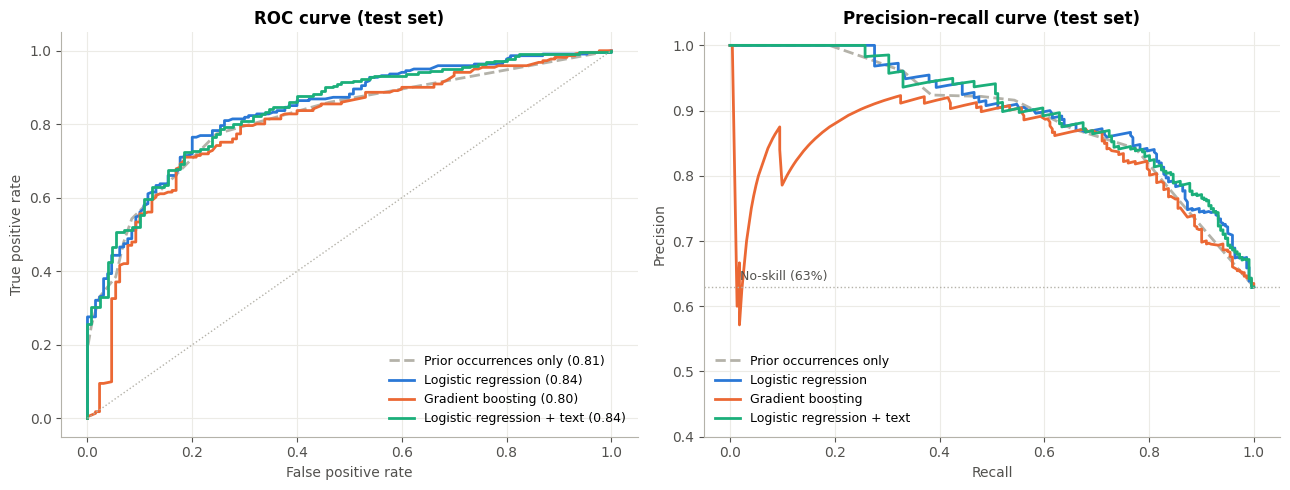

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = {'Logistic regression': BLUE, 'Gradient boosting': ORANGE, 'Logistic regression + text': AQUA}
base = X_test['prior_occurrence_count']

ax = axes[0]
fpr, tpr, _ = roc_curve(y_test, base)
ax.plot(fpr, tpr, color=GRAY, lw=2, ls='--', label=f"Prior occurrences only ({results['Baseline: prior occurrences only'][0]:.2f})")
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=colors[name], lw=2, label=f'{name} ({results[name][0]:.2f})')
ax.plot([0, 1], [0, 1], color=GRAY, lw=1, ls=':')
ax.set_title('ROC curve (test set)'); ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.legend(loc='lower right', fontsize=9)

ax = axes[1]
prec, rec, _ = precision_recall_curve(y_test, base)
ax.plot(rec, prec, color=GRAY, lw=2, ls='--', label='Prior occurrences only')
for name, p in probs.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax.plot(rec, prec, color=colors[name], lw=2, label=name)
ax.axhline(y_test.mean(), color=GRAY, lw=1, ls=':')
ax.text(0.02, y_test.mean() + 0.01, f'No-skill ({y_test.mean():.0%})', color=MUTED, fontsize=9)
ax.set_title('Precision–recall curve (test set)'); ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_ylim(0.4, 1.02); ax.legend(loc='lower left', fontsize=9)
plt.tight_layout(); fig.savefig(f'{FIG_DIR}/07_model_curves.png', dpi=150, bbox_inches='tight'); plt.show()

## 8. Pick the final model and choose a threshold
We keep the **simplest model that performs as well as the others**. Then we turn probabilities into a yes/no flag.
For QA, missing a recurring problem is worse than an extra look at one that wouldn't recur, so we pick the threshold that
flags roughly the top half of findings for deeper root-cause analysis and report what that catches.

In [8]:
model_rank = scores.drop(index=[i for i in scores.index if i.startswith('Baseline')])
best_auc = model_rank['ROC-AUC'].max()
# Simplest model within 0.01 ROC-AUC of the best (models are listed simplest first)
FINAL = next(n for n in models if model_rank.loc[n, 'ROC-AUC'] >= best_auc - 0.01)
final_model, p_final = models[FINAL], probs[FINAL]
print(f'Final model: {FINAL}')

THRESHOLD = float(np.quantile(p_final, 0.5))     # flag the top 50% of findings
flag = p_final >= THRESHOLD
tn, fp, fn, tp = confusion_matrix(y_test, flag).ravel()
print(f'Threshold: {THRESHOLD:.2f} (flags {flag.mean():.0%} of new findings)')
print(f'Precision: {precision_score(y_test, flag):.0%}  (of flagged findings, share that really recurred)')
print(f'Recall:    {recall_score(y_test, flag):.0%}  (of findings that recurred, share we flagged)')
print(f'Recurrence rate among flagged: {y_test[flag].mean():.0%} vs not flagged: {y_test[~flag].mean():.0%}')
pd.DataFrame([[tn, fp], [fn, tp]], index=['Actually did not recur', 'Actually recurred'],
             columns=['Not flagged', 'Flagged'])

Final model: Logistic regression
Threshold: 0.81 (flags 50% of new findings)
Precision: 87%  (of flagged findings, share that really recurred)
Recall:    69%  (of findings that recurred, share we flagged)
Recurrence rate among flagged: 87% vs not flagged: 39%


,Not flagged,Flagged
Actually did not recur,107,23
Actually recurred,68,153


## 9. What drives the prediction?
For logistic regression, each coefficient shows how a feature pushes the odds of recurrence up or down
(after one-hot encoding). Positive = more likely to recur.

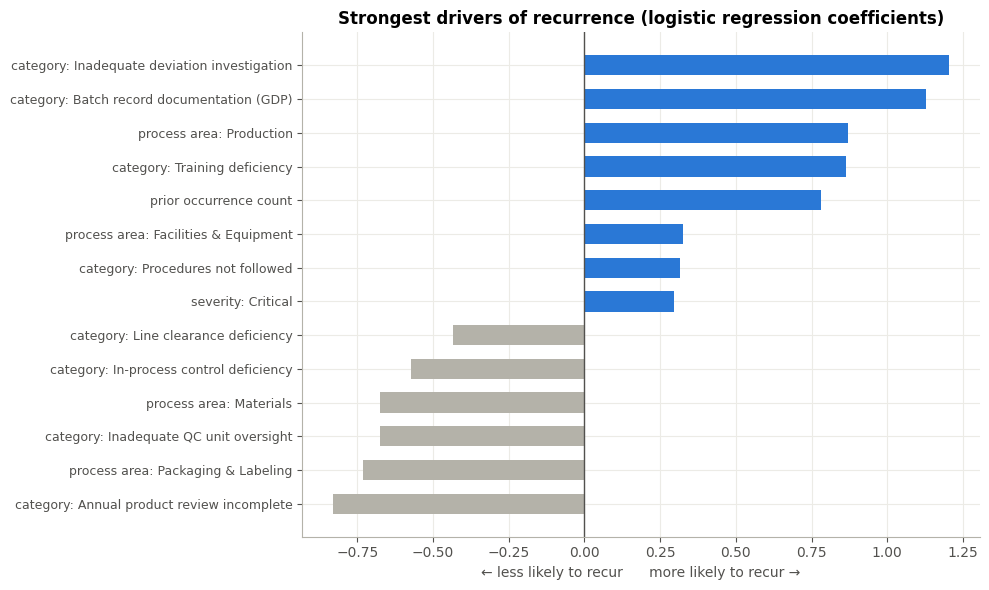

In [9]:
if 'Logistic regression' in FINAL:
    ct, lr = final_model[0], final_model[-1]
    def label(raw):
        name = raw.split('__', 1)[1]                        # drop the 'cat__' / 'num__' prefix
        for c in CATEGORICAL:
            if name.startswith(c + '_'):
                return f"{c.replace('_', ' ')}: {name[len(c) + 1:]}"
        return name.replace('_', ' ')
    names = [label(n) for n in ct.get_feature_names_out()]
    coefs = pd.Series(lr.coef_[0], index=names)
    top = pd.concat([coefs.nlargest(8), coefs.nsmallest(6)]).sort_values()

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top.index, top.values, color=[BLUE if v > 0 else GRAY for v in top.values], height=0.6)
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_title('Strongest drivers of recurrence (logistic regression coefficients)')
    ax.set_xlabel('← less likely to recur      more likely to recur →'); ax.tick_params(axis='y', labelsize=9)
    plt.tight_layout(); fig.savefig(f'{FIG_DIR}/08_model_drivers.png', dpi=150, bbox_inches='tight'); plt.show()
else:
    print('Final model is not logistic regression; see permutation importance instead.')

## 10. For comparison: predicting overdue CAPAs
The original roadmap suggested predicting which CAPAs go overdue. Here is the same approach applied to that target.

In [10]:
od = df[df['due_date'] <= SNAPSHOT].copy()
od['late'] = ~((od['status'] == 'Closed') & (od['close_date'] <= od['due_date']))
od_tr, od_te = od[od['audit_date'] < pd.Timestamp('2025-10-01')], od[od['audit_date'] >= pd.Timestamp('2025-10-01')]
od_model = make_pipeline(ColumnTransformer(structured()), LogisticRegression(max_iter=3000, C=0.5))
od_model.fit(od_tr[FEATURES], od_tr['late'])
od_p = od_model.predict_proba(od_te[FEATURES])[:, 1]
OD_AUC = roc_auc_score(od_te['late'], od_p)
print(f'Overdue model ROC-AUC: {OD_AUC:.2f} (late rate {od_te.late.mean():.0%})')
print('\nLate rate by site:')
print(od.groupby('site_name')['late'].mean().map('{:.0%}'.format).to_string())

Overdue model ROC-AUC: 0.65 (late rate 21%)

Late rate by site:
site_name
Basel, Switzerland    16%
Cork, Ireland         37%
Hyderabad, India      12%
Raleigh, NC           15%
San Juan, PR          17%


The overdue model is much weaker. That is an honest result: in this synthetic data, the only planted driver of
late CAPAs is the site (Cork), so there is little else for a model to learn. With real data, workload, CAPA owner,
and action complexity would likely add signal. **Reporting a weak model honestly is better than overselling it.**

## 11. Save the final model for the app (Phase 7)
The model is retrained on **all** labeled findings (train + test) so it learns from the most recent data, then saved
with a small metadata file describing what it expects.

In [11]:
deploy_model = models[FINAL]
deploy_model.fit(labeled[FEATURES], labeled[TARGET])
joblib.dump(deploy_model, f'{MODELS_DIR}/recurrence_model.joblib')

meta = {
    'model': FINAL,
    'target': 'Same problem cited again on the same item at the same site within 12 months',
    'features': FEATURES,
    'categories': {c: sorted(df[c].dropna().unique().tolist()) for c in CATEGORICAL},
    'threshold': round(THRESHOLD, 3),
    'test_metrics': {'roc_auc': round(float(scores.loc[FINAL, 'ROC-AUC']), 3),
                     'pr_auc': round(float(scores.loc[FINAL, 'PR-AUC']), 3),
                     'baseline_prior_only_roc_auc': round(float(scores.loc['Baseline: prior occurrences only', 'ROC-AUC']), 3)},
    'train_period': f'{train.audit_date.min().date()} to {train.audit_date.max().date()}',
    'test_period': f'{test.audit_date.min().date()} to {test.audit_date.max().date()}',
    'sklearn_version': sklearn.__version__,
}
with open(f'{MODELS_DIR}/recurrence_model_meta.json', 'w') as f:
    json.dump(meta, f, indent=2)
print(f'Saved → {MODELS_DIR}/recurrence_model.joblib')
print(f'Saved → {MODELS_DIR}/recurrence_model_meta.json')
print(f"\nPin this in requirements.txt for Phase 7: scikit-learn=={sklearn.__version__}")

Saved → /content/drive/MyDrive/gmp-audit-risk-dashboard/models/recurrence_model.joblib
Saved → /content/drive/MyDrive/gmp-audit-risk-dashboard/models/recurrence_model_meta.json

Pin this in requirements.txt for Phase 7: scikit-learn==1.6.1


## 12. Summary for your README

In [12]:
gain = scores.loc[FINAL, 'ROC-AUC'] - scores.loc['Baseline: prior occurrences only', 'ROC-AUC']
text_gain = scores.loc['Logistic regression + text', 'ROC-AUC'] - scores.loc['Logistic regression', 'ROC-AUC']
summary = f'''
**Model:** {FINAL}, predicting whether a finding recurs on the same item within 12 months.
**Validation:** time-based split, trained on {meta['train_period']}, tested on {meta['test_period']}.
**Result:** ROC-AUC {scores.loc[FINAL, 'ROC-AUC']:.2f}, PR-AUC {scores.loc[FINAL, 'PR-AUC']:.2f}
(no-skill PR-AUC {y_test.mean():.2f}).
**Versus a simple baseline:** ranking by prior occurrences alone scores ROC-AUC
{scores.loc['Baseline: prior occurrences only', 'ROC-AUC']:.2f}, so the model adds {gain:+.2f}.
Most of the signal is "this has happened before here"; the model adds category and site context.
**Text features:** TF-IDF on descriptions changed ROC-AUC by {text_gain:+.3f}, because synthetic descriptions are
template-based. Real free-text findings would likely carry more signal.
**Comparison:** predicting overdue CAPAs reached only ROC-AUC {OD_AUC:.2f}; the synthetic data plants little signal
for lateness beyond site.
**Limitation:** the model can only rediscover patterns designed into the synthetic data. The value shown here is a
leakage-free, time-validated pipeline, ready to retrain on real data.
'''.strip()
from IPython.display import Markdown, display
display(Markdown(summary))
with open(f'{MODELS_DIR}/model_summary.md', 'w') as f:
    f.write('# Model summary\n\n' + summary + '\n')

**Model:** Logistic regression, predicting whether a finding recurs on the same item within 12 months.
**Validation:** time-based split, trained on 2023-10-09 to 2024-12-24, tested on 2025-01-01 to 2025-09-29.
**Result:** ROC-AUC 0.84, PR-AUC 0.90
(no-skill PR-AUC 0.63).
**Versus a simple baseline:** ranking by prior occurrences alone scores ROC-AUC
0.81, so the model adds +0.02.
Most of the signal is "this has happened before here"; the model adds category and site context.
**Text features:** TF-IDF on descriptions changed ROC-AUC by +0.001, because synthetic descriptions are
template-based. Real free-text findings would likely carry more signal.
**Comparison:** predicting overdue CAPAs reached only ROC-AUC 0.65; the synthetic data plants little signal
for lateness beyond site.
**Limitation:** the model can only rediscover patterns designed into the synthetic data. The value shown here is a
leakage-free, time-validated pipeline, ready to retrain on real data.

## Next steps
1. Check `models/` in Drive: `recurrence_model.joblib`, `recurrence_model_meta.json`, `model_summary.md`.
2. Note the **scikit-learn version** printed in Section 11; Phase 7 needs it.
3. **File → Save a copy in GitHub** → `notebooks/04_ml_model.ipynb`.
4. Add decision **D9** (the target choice) to `design_decisions.md`.